In [1]:
import logging

import numpy as np
import optimistix as optx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy.signal import savgol_filter


logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [2]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)


species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
    )
)

In [3]:
number_of_realisations = 50
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

ALL_VALUES = []

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

## Hydrogen fraction

Where does saturation occur

In [4]:
import numpy as np

# ===========================================================
# 1. Lodders (2009) solar composition mass fractions (wt%)
# ===========================================================
H_masspercent_lodders09  = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09  = 0.22
N_masspercent_lodders09  = 0.07
O_masspercent_lodders09  = 0.63

# Ratios relative to hydrogen (Solar)
C_H_RATIO_SOLAR  = C_masspercent_lodders09  / H_masspercent_lodders09
N_H_RATIO_SOLAR  = N_masspercent_lodders09  / H_masspercent_lodders09
O_H_RATIO_SOLAR  = O_masspercent_lodders09  / H_masspercent_lodders09
He_H_RATIO_SOLAR = He_masspercent_lodders09 / H_masspercent_lodders09


# ===========================================================
# 2. Function to get metal-enriched budgets
# ===========================================================
def get_enriched_budget(h_kg, metallicity_factor=100):
    """
    Returns C, N, O, and He masses based on solar H ratios,
    with C, N, O enriched by metallicity_factor × solar.
    He stays fixed at the solar He/H ratio.
    """
    return {
        "H":  h_kg,
        "C":  h_kg * C_H_RATIO_SOLAR  * metallicity_factor,
        "N":  h_kg * N_H_RATIO_SOLAR  * metallicity_factor,
        "He": h_kg * He_H_RATIO_SOLAR
    }


# ===========================================================
# 3. Hydrogen mass fraction range: 0.1% → 10% of total planet mass
# ===========================================================
number_of_realisations = 50   # choose as needed

# Hydrogen mass fractions between 0.001 and 0.10
H_mass_fraction = np.logspace(-3, -1, number_of_realisations)
fO2_log10_shifts = np.full(number_of_realisations, -6)

# Convert mass fraction → hydrogen mass in kg
h_kg = H_mass_fraction * planet_mass

mass_constraints = get_enriched_budget(h_kg, metallicity_factor=100)

In [5]:
mass_constraints = get_enriched_budget(h_kg)

In [6]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

In [53]:
solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)
model_ideal_varyfO2andH_withsol = InteriorAtmosphere(species_real)

fugacity_constraints = {O2_g.name: IronWustiteBuffer(fO2_log10_shifts)}

model_ideal_varyfO2andH_withsol.solve(
    planet=sub_neptune,
    mass_constraints=mass_constraints,
    fugacity_constraints=fugacity_constraints,
    solver_parameters=solver_parameters,
)

output_model_ideal_varyfO2andH_withsol = model_ideal_varyfO2andH_withsol.output

# Write the complete solution to Excel
file = output_model_ideal_varyfO2andH_withsol.to_excel("FILE40")

# Write the data to a pickle file with dataframes
output_model_ideal_varyfO2andH_withsol.to_pickle("FILE40")



[22:09:00 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[22:09:00 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[22:09:00 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[22:09:00 - atmodeller.classes             - IN

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap
from matplotlib.ticker import ScalarFormatter, FixedLocator

# ===========================================================
# STYLE
# ===========================================================
def set_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["axes.labelsize"] = 15
    plt.rcParams["axes.titlesize"] = 16
    plt.rcParams["legend.fontsize"] = 12
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.alpha"] = 0.4

# Stacked area colors (unchanged)
palette = get_cmap("Set2")(np.linspace(0, 1, 4))

# Ratio line colors
ratio_colors = {
    "mass": "black",
    "mole": "black"
}

# ===========================================================
# HELPERS
# ===========================================================
def load_species(file, sheet):
    return pd.read_excel(file, sheet_name=sheet)

def compute_mass_partition(df_H2O, df_H2):
    H2O_atm = df_H2O["atmosphere_mass"]
    H2O_mag = df_H2O["dissolved_mass"]
    H2_atm  = df_H2["atmosphere_mass"]
    H2_mag  = df_H2["dissolved_mass"]
    total = H2O_atm + H2O_mag + H2_atm + H2_mag
    return (H2O_atm/total, H2O_mag/total, H2_atm/total, H2_mag/total)

def compute_mole_partition(df_H2O, df_H2):
    H2O_atm = df_H2O["atmosphere_moles"]
    H2O_mag = df_H2O["dissolved_moles"]
    H2_atm  = df_H2["atmosphere_moles"]
    H2_mag  = df_H2["dissolved_moles"]
    total = H2O_atm + H2O_mag + H2_atm + H2_mag
    return (H2O_atm/total, H2O_mag/total, H2_atm/total, H2_mag/total)

def get_x_axis(df_H2O, df_H2, planet_mass):
    return (df_H2O["total_mass"] + df_H2["total_mass"]) / planet_mass

def load_mass_frac(file):
    df_H2  = pd.read_excel(file, sheet_name="H2_g")
    df_H2O = pd.read_excel(file, sheet_name="H2O_g")
    return df_H2["atmosphere_mass"] / df_H2O["atmosphere_mass"]

def load_moles_frac(file):
    df_H2  = pd.read_excel(file, sheet_name="H2_g")
    df_H2O = pd.read_excel(file, sheet_name="H2O_g")
    return df_H2["atmosphere_moles"] / df_H2O["atmosphere_moles"]

def mmw(file):

    molar_masses = {
    'H2_g': 2.016,
    'H2O_g': 18.015,
    'CO_g': 28.010,
    'CO2_g': 44.009,
    'CH4_g': 16.043,
    'N2_g': 28.014,
    'O2_g': 31.998,
    'H3N_g': 17.031,
    'He_g': 4.003,
    }

    mmw = 0
    
    for species, molar_mass in molar_masses.items():
        df = pd.read_excel(file, sheet_name=species)
        volume_mixing_ratio = df["volume_mixing_ratio"]
        weight = volume_mixing_ratio * molar_mass
        mmw += weight

    return mmw

# ===========================================================
# MAIN FUNCTION
# ===========================================================
def plot_all(files, outfile="partitioning_plots.png"):

    set_style()

    mantle_values = [+3, 0, -3]
    x_ticks = [0.1, 1, 10]

    fig, axes = plt.subplots(3, 2, figsize=(14, 18), dpi=200)

    # Global title
    fig.suptitle("H₂ and H₂O Partitioning with varying oxygen fugacity ($fO_{{2}}$)", fontsize=22, y=0.96)

    for i, file in enumerate(files):

        df_planet = pd.read_excel(file, sheet_name="planet")
        df_H = pd.read_excel(file, sheet_name="element_H")
        df_H2O = load_species(file, "H2O_g")
        df_H2  = load_species(file, "H2_g")

        planet_mass = df_planet["planet_mass"].iloc[0]
        XX = (df_H["total_mass"] / planet_mass) * 100

        # 4-area partitions
        mf_H2O_atm, mf_H2O_mag, mf_H2_atm, mf_H2_mag = compute_mass_partition(df_H2O, df_H2)
        xf_H2O_atm, xf_H2O_mag, xf_H2_atm, xf_H2_mag = compute_mole_partition(df_H2O, df_H2)

        # Ratio lines
        mass_ratio = load_mass_frac(file)
        mole_ratio = load_moles_frac(file)

        Mfrac = mantle_values[i]
        MMW = mmw(file)

        # =====================================================
        # LEFT COLUMN — MASS FRACTION
        # =====================================================
        ax = axes[i, 0]

        ax.stackplot(
            XX,
            mf_H2O_atm, mf_H2O_mag, mf_H2_atm, mf_H2_mag,
            labels=["H₂O atm", "H₂O magma", "H₂ atm", "H₂ magma"],
            colors=palette, alpha=0.85
        )

        ax.set_xscale("log")
        ax.set_xlim(min(XX), max(XX))
        ax.xaxis.set_major_locator(FixedLocator(x_ticks))

        fmt = ScalarFormatter(); fmt.set_scientific(False)
        ax.xaxis.set_major_formatter(fmt)

        ax.set_ylim(0, 1)
        ax.set_ylabel("Partitioning (Mass Fraction)")
        ax.set_xlabel("Total Hydrogen Mass / Planet Mass  [%]")

        ax.set_title(f"Mass fraction, $fO_{{2}}$ = {Mfrac}")

        # MASS RATIO LINE
        ax_mmw = ax.twinx()
        mass_line = ax_mmw.plot(
            XX, MMW,
            color=ratio_colors["mass"],
            lw=2.3,
            label="mean molecular weight"
        )[0]
        ax_mmw.set_ylabel("mean molecular weight")

        # Legend
        handles1, labels1 = ax.get_legend_handles_labels()
        handles = handles1 + [mass_line]
        labels  = labels1 + ["H₂/H₂O (mass)"]
        if i == 0:
            ax.legend(handles, labels, loc="upper left", frameon=True, fontsize=10)

        # =====================================================
        # RIGHT COLUMN — MOLE FRACTION
        # =====================================================
        ax2 = axes[i, 1]

        ax2.stackplot(
            XX,
            xf_H2O_atm, xf_H2O_mag, xf_H2_atm, xf_H2_mag,
            labels=["H₂O atm", "H₂O magma", "H₂ atm", "H₂ magma"],
            colors=palette, alpha=0.85
        )

        ax2.set_xscale("log")
        ax2.set_xlim(min(XX), max(XX))
        ax2.xaxis.set_major_locator(FixedLocator(x_ticks))
        ax2.xaxis.set_major_formatter(fmt)

        ax2.set_ylim(0, 1)
        ax2.set_ylabel("Partitioning (Mole Fraction)")
        ax2.set_xlabel("Total Hydrogen Mass / Planet Mass  [%]")

        ax2.set_title(f"Mole fraction, $fO_{{2}}$ = {Mfrac}")

        # MOLE RATIO LINE
        ax3 = ax2.twinx()
        mole_line = ax3.plot(
            XX, MMW,
            color=ratio_colors["mole"],
            lw=2.3,
            label="mmw"
        )[0]
        ax3.set_ylabel("Mean molecular weight")

        # Legend
        handles2, labels2 = ax2.get_legend_handles_labels()
        handles2 = handles2 + [mole_line]
        labels2  = labels2 + ["H₂/H₂O (mole)"]
        if i == 0:
            ax2.legend(handles2, labels2, loc="upper left", frameon=True, fontsize=10)

    plt.subplots_adjust(wspace=0.5, hspace=0.35)
    plt.tight_layout(rect=[0, 0, 1, 0.96])  # leave space for global title
    plt.savefig(outfile, dpi=300, bbox_inches="tight")
    plt.show()


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_23127/504971967.py:21: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = get_cmap("Set2")(np.linspace(0, 1, 4))


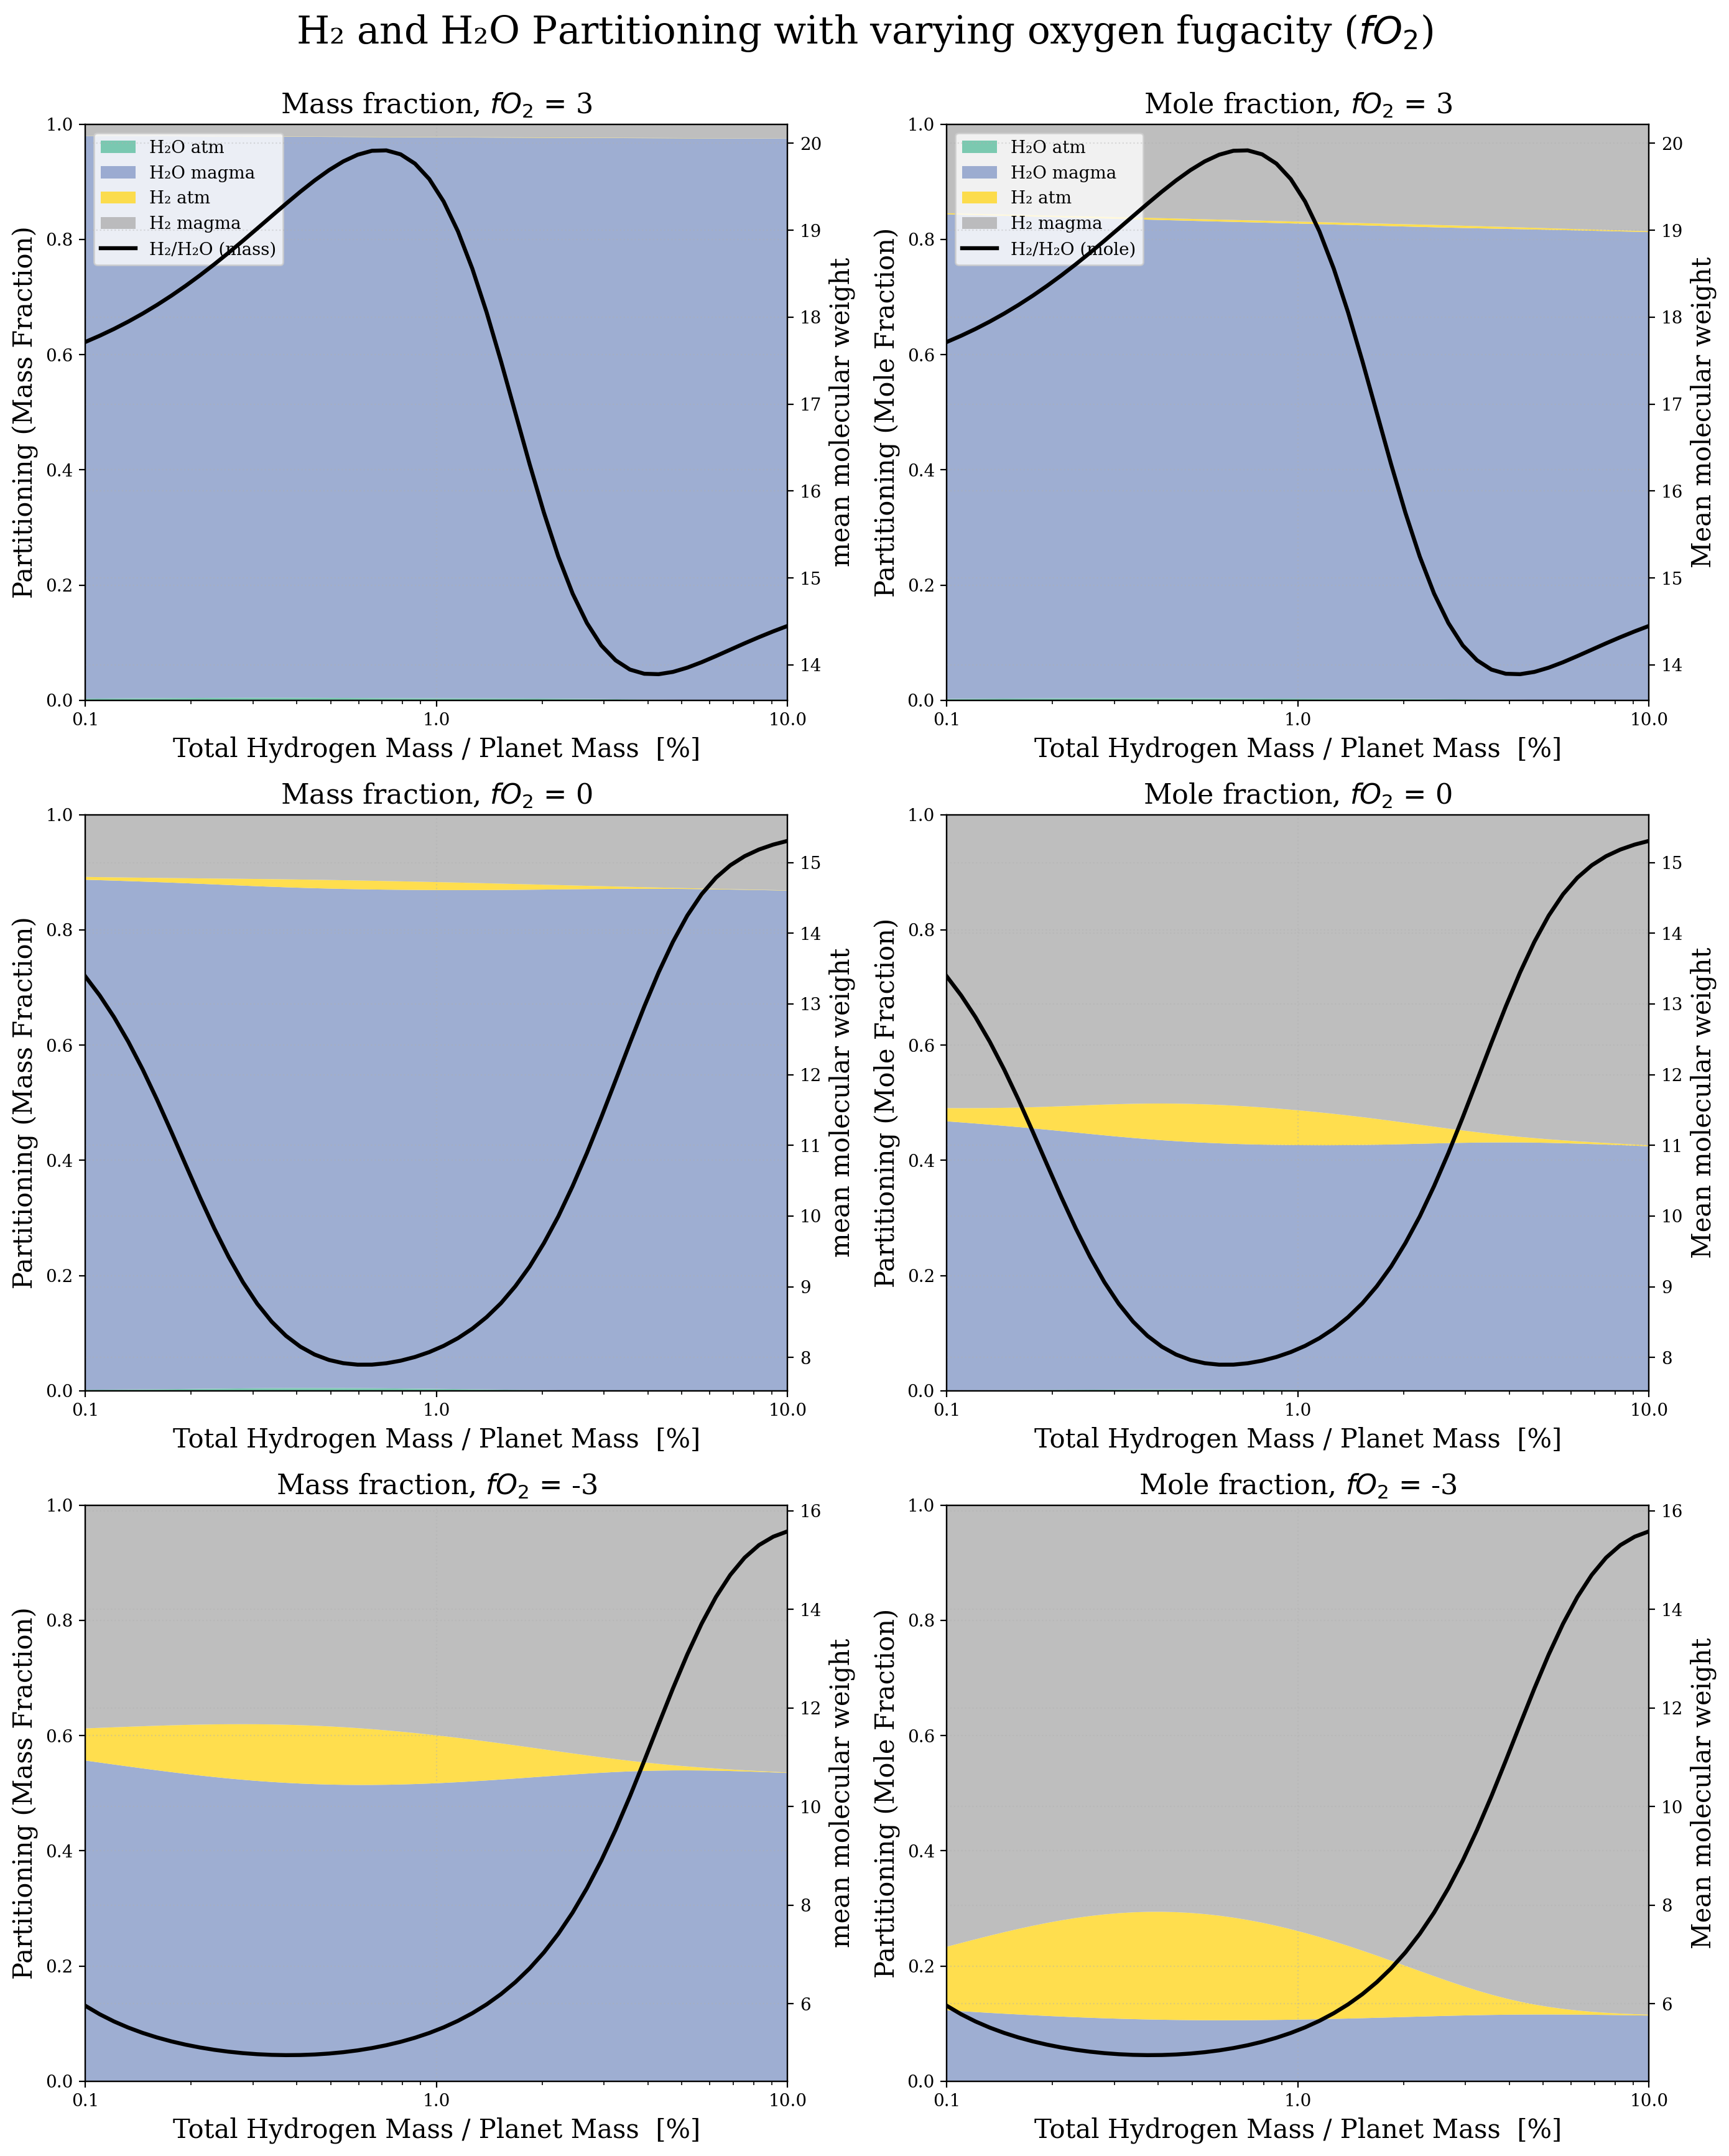

In [8]:
plot_all(["FILE27.xlsx", "FILE28.xlsx", "FILE300.xlsx"])


In [17]:
# ===========================================================
# NATURE-STYLE PLOTTING + ENLARGED TITLES & LEGENDS
# ===========================================================
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib import colormaps
import numpy as np
import pandas as pd

def set_nature_style():
    """
    Full Nature-quality styling based on your atmospheric plots.
    """
    plt.rcdefaults()
    plt.rcParams["font.family"]        = "serif"
    plt.rcParams["font.serif"]         = ["Times New Roman", "DejaVu Serif"]

    # Larger sizes for paper printing
    plt.rcParams["axes.titlesize"]     = 20
    plt.rcParams["axes.labelsize"]     = 18
    plt.rcParams["xtick.labelsize"]    = 16
    plt.rcParams["ytick.labelsize"]    = 16
    plt.rcParams["legend.fontsize"]    = 16

    plt.rcParams["axes.linewidth"]     = 1.2
    plt.rcParams["axes.grid"]          = True
    plt.rcParams["grid.linestyle"]     = ":"
    plt.rcParams["grid.linewidth"]     = 0.5
    plt.rcParams["grid.alpha"]         = 0.45

    plt.rcParams["axes.prop_cycle"]    = plt.cycler(color=colormaps["tab10"].colors)


# ===========================================================
# UPDATED MAIN FUNCTION — Nature Style
# ===========================================================
def plot_all(files, outfile="partitioning_plots.png"):

    set_nature_style()

    mantle_values = [0, -3, -6]
    x_ticks = [0.1, 1, 10]

    fig, axes = plt.subplots(
        3, 2,
        figsize=(15, 20),   # much larger for publication
        dpi=300,
        layout="constrained"
    )

    fig.suptitle(
        r"H$_2$ and H$_2$O Partitioning for Different Oxygen Fugacities ($fO_2$)",
        fontsize=26, 
        y=1.03, 
        ha="center"
    )

    for i, file in enumerate(files):

        df_planet = pd.read_excel(file, sheet_name="planet")
        df_H = pd.read_excel(file, sheet_name="element_H")
        df_H2O = load_species(file, "H2O_g")
        df_H2  = load_species(file, "H2_g")

        planet_mass = df_planet["planet_mass"].iloc[0]
        XX = (df_H["total_mass"] / planet_mass) * 100

        # Compute mass/mole partitions
        mf = compute_mass_partition(df_H2O, df_H2)
        xf = compute_mole_partition(df_H2O, df_H2)

        # Ratio lines
        MMW = mmw(file)

        # -------------------------------------------------------
        # LEFT COLUMN — MASS FRACTION
        # -------------------------------------------------------
        ax = axes[i, 0]

        ax.stackplot(
            XX, *mf,
            labels=["H$_2$O (atm)", "H$_2$O (magma)", "H$_2$ (atm)", "H$_2$ (magma)"],
            colors=palette, alpha=0.9
        )

        ax.set_xscale("log")
        ax.set_xlim(min(XX), max(XX))
        ax.xaxis.set_major_locator(FixedLocator(x_ticks))

        fmt = ScalarFormatter()
        fmt.set_scientific(False)
        ax.xaxis.set_major_formatter(fmt)

        ax.set_ylim(0, 1)
        ax.set_ylabel("Mass Fraction", fontsize=18)
        ax.set_xlabel("Hydrogen Mass / Planet Mass [%]", fontsize=18)

        ax.set_title(
            rf"Mass Fraction, $\Delta$IW = {mantle_values[i]}",
            fontsize=20
        )

        # Add molecular weight overlay
        ax_mmw = ax.twinx()
        mw_line = ax_mmw.plot(
            XX, MMW,
            color="black",
            lw=2.8,
            label="Mean molecular weight $\mu_{atm}$"
        )[0]
        ax_mmw.set_ylabel("Mean molecular weight, $\mu_{atm}$", fontsize=18)

        # Legend only on top row
        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            handles.append(mw_line)
            labels.append("Mean molecular weight $\mu_{atm}$")
            ax.legend(
                handles, labels,
                frameon=True,
                loc="lower left",
                fontsize=16
            )

        # -------------------------------------------------------
        # RIGHT COLUMN — MOLE FRACTION
        # -------------------------------------------------------
        ax2 = axes[i, 1]

        ax2.stackplot(
            XX, *xf,
            labels=["H$_2$O (atm)", "H$_2$O (magma)", "H$_2$ (atm)", "H$_2$ (magma)"],
            colors=palette,
            alpha=0.9
        )

        ax2.set_xscale("log")
        ax2.set_xlim(min(XX), max(XX))
        ax2.xaxis.set_major_locator(FixedLocator(x_ticks))
        ax2.xaxis.set_major_formatter(fmt)

        ax2.set_ylim(0, 1)
        ax2.set_ylabel("Mole Fraction", fontsize=18)
        ax2.set_xlabel("Hydrogen Mass / Planet Mass [%]", fontsize=18)

        ax2.set_title(
            rf"Mole Fraction, $\Delta$IW = {mantle_values[i]}",
            fontsize=20
        )

        # Molecular weight
        ax3 = ax2.twinx()
        mw_line2 = ax3.plot(
            XX, MMW,
            color="black",
            lw=2.8,
            label="Mean molecular weight $\mu_{atm}$"
        )[0]
        ax3.set_ylabel("Mean molecular weight, $\mu_{atm}$", fontsize=18)

        if i == 0:
            handles2, labels2 = ax2.get_legend_handles_labels()
            handles2.append(mw_line2)
            labels2.append("Mean molecular weight $\mu_{atm}$")
            ax2.legend(
                handles2, labels2,
                frameon=True,
                loc="lower left",
                fontsize=16
            )

    # Save high-resolution figure
    plt.savefig(outfile, dpi=350, bbox_inches="tight")
    plt.show()


<>:109: SyntaxWarning: invalid escape sequence '\m'
<>:111: SyntaxWarning: invalid escape sequence '\m'
<>:117: SyntaxWarning: invalid escape sequence '\m'
<>:157: SyntaxWarning: invalid escape sequence '\m'
<>:159: SyntaxWarning: invalid escape sequence '\m'
<>:164: SyntaxWarning: invalid escape sequence '\m'
<>:109: SyntaxWarning: invalid escape sequence '\m'
<>:111: SyntaxWarning: invalid escape sequence '\m'
<>:117: SyntaxWarning: invalid escape sequence '\m'
<>:157: SyntaxWarning: invalid escape sequence '\m'
<>:159: SyntaxWarning: invalid escape sequence '\m'
<>:164: SyntaxWarning: invalid escape sequence '\m'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_65623/1751916358.py:109: SyntaxWarning: invalid escape sequence '\m'
  label="Mean molecular weight $\mu_{atm}$"
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_65623/1751916358.py:111: SyntaxWarning: invalid escape sequence '\m'
  ax_mmw.set_ylabel("Mean molecular weight, $\mu_{atm}$", fontsize=18)
/var/

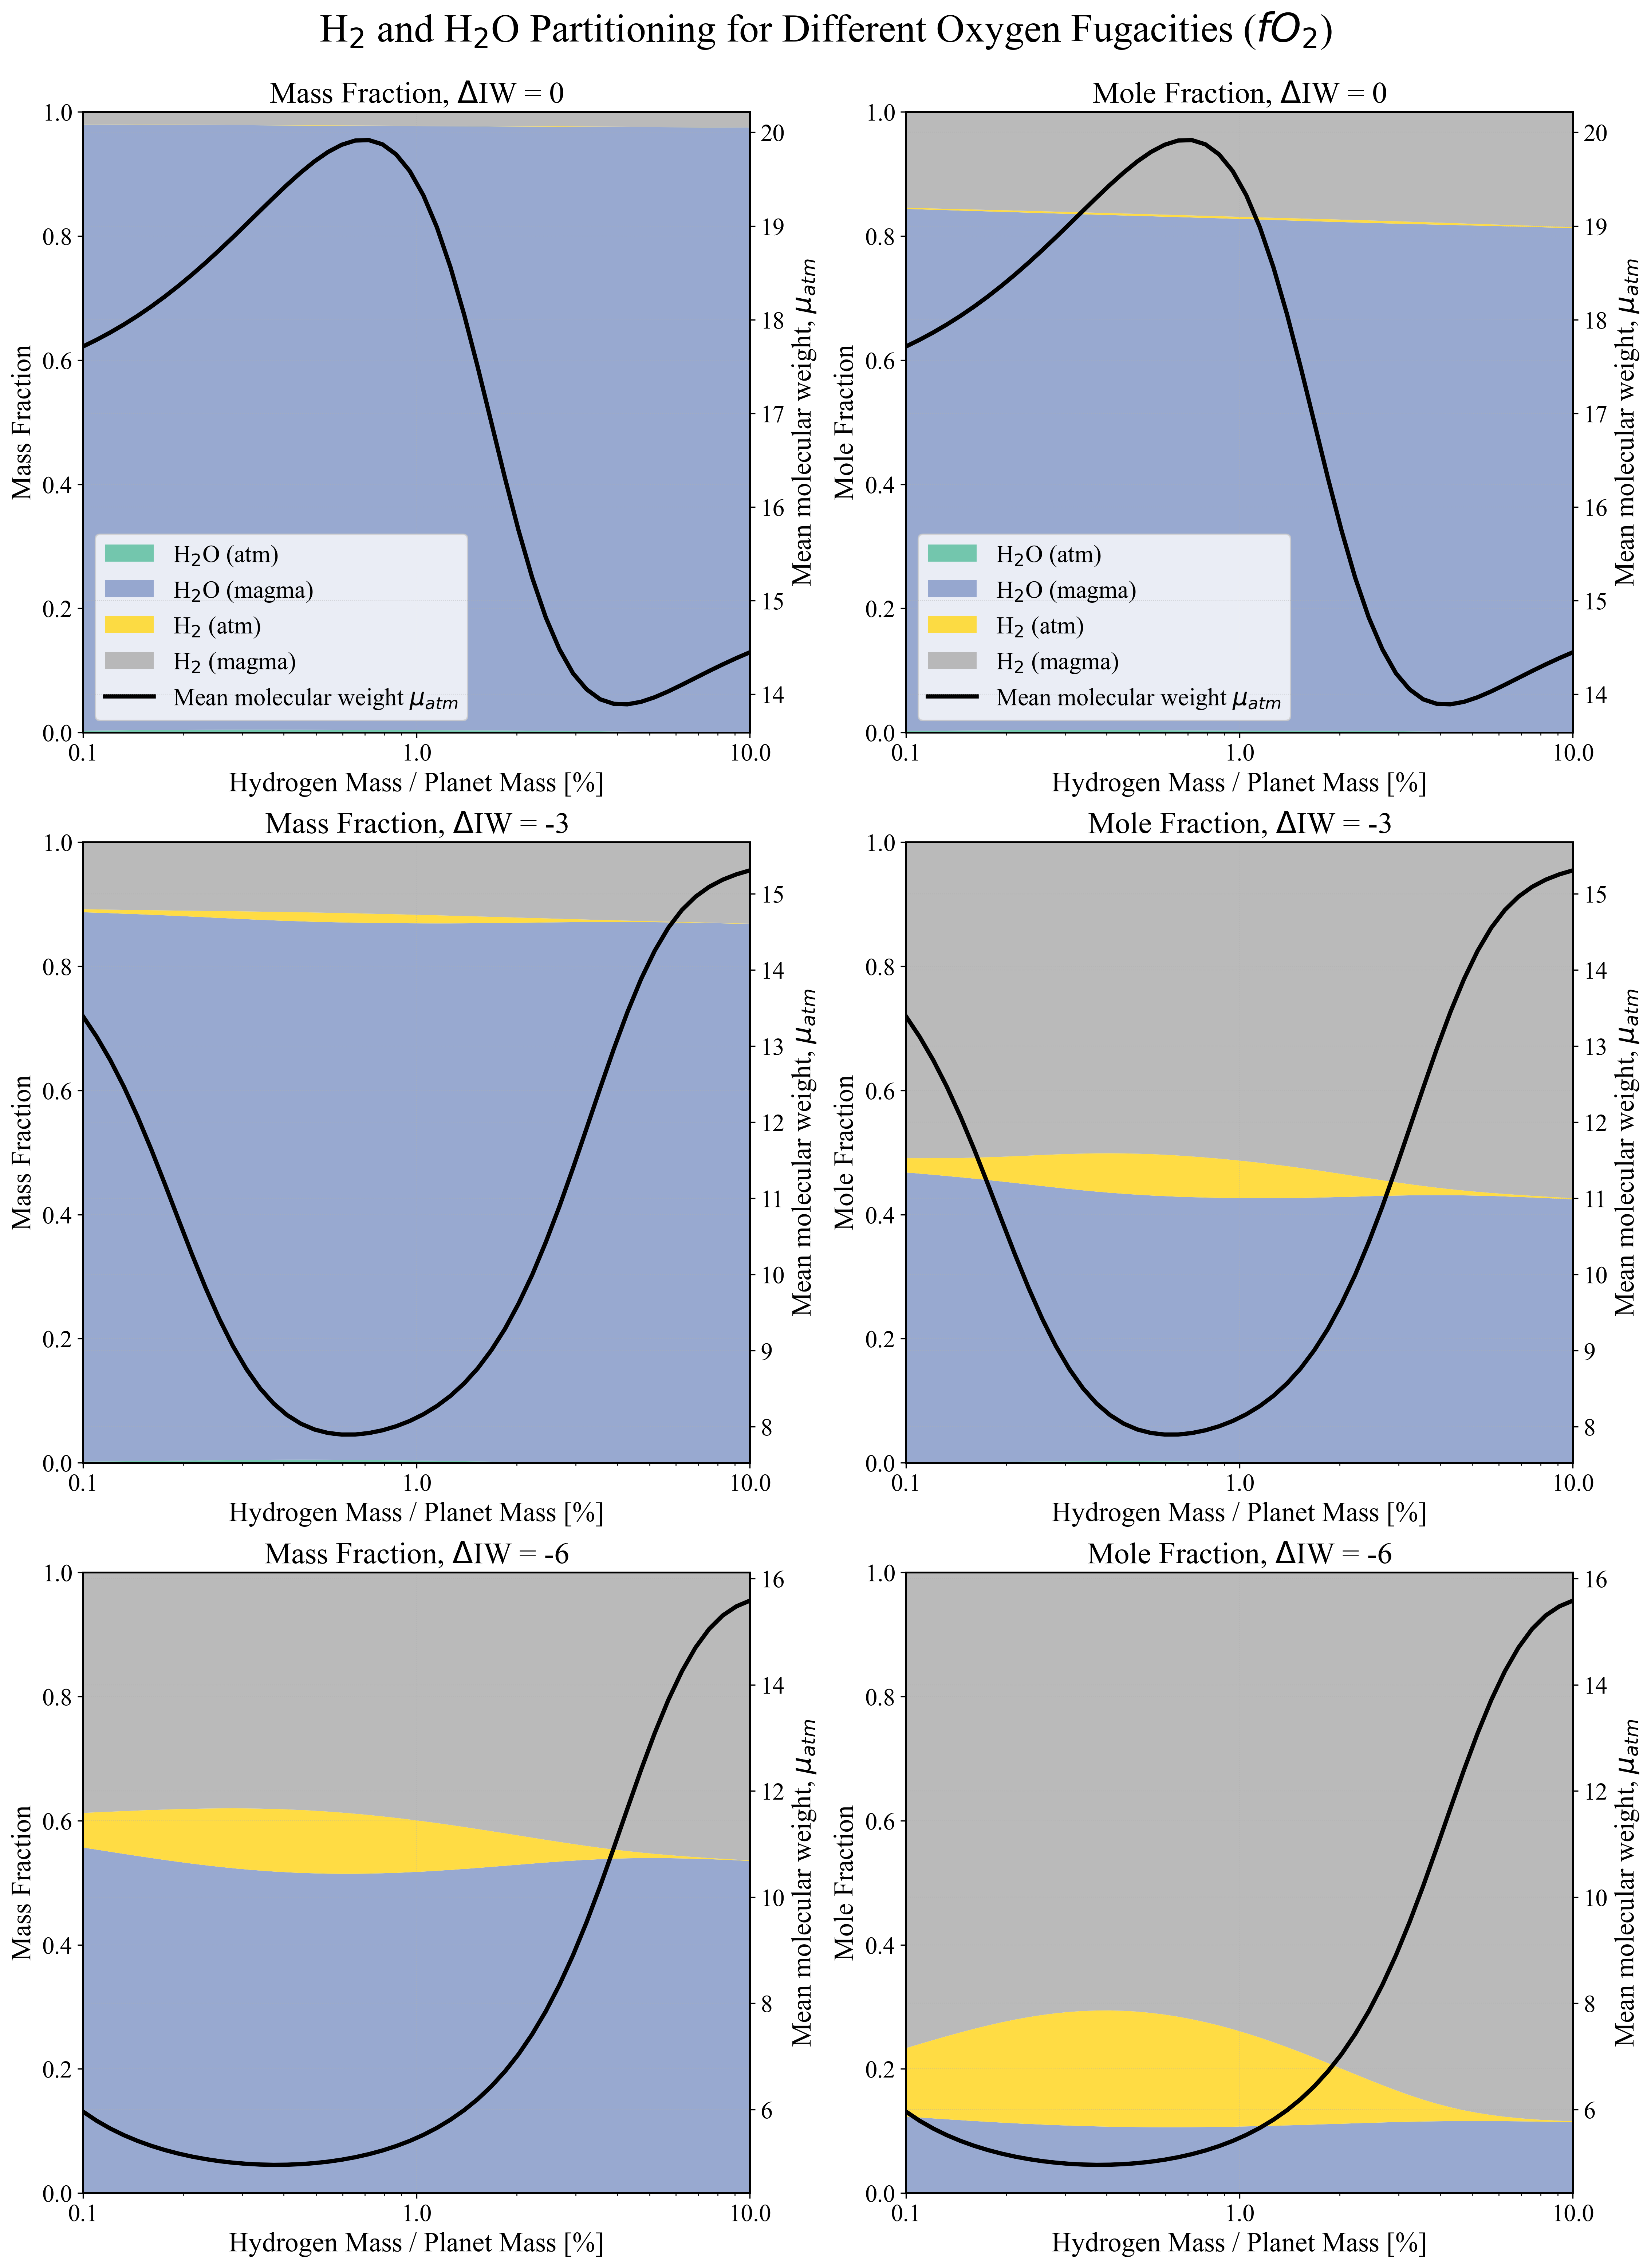

In [18]:
plot_all(["FILE27.xlsx", "FILE28.xlsx", "FILE300.xlsx"])


In [20]:
# ===========================================================
# NATURE-STYLE PLOTTING — SEPARATE FIGURES + RIGHT LEGENDS
# ===========================================================
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.ticker import FixedLocator, ScalarFormatter
from matplotlib import colormaps
import numpy as np
import pandas as pd


def set_nature_style():
    plt.rcdefaults()
    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "DejaVu Serif"],
        "axes.titlesize": 28,
        "axes.labelsize": 24,
        "xtick.labelsize": 20,
        "ytick.labelsize": 20,
        "legend.fontsize": 20,
        "axes.linewidth": 1.2,
        "axes.grid": True,
        "grid.linestyle": ":",
        "grid.linewidth": 0.5,
        "grid.alpha": 0.45,
        "axes.prop_cycle": plt.cycler(color=colormaps["tab10"].colors),
    })


# ===========================================================
# MAIN FUNCTION — ONE FIGURE PER PLOT
# ===========================================================
def plot_all(files, outprefix="partitioning"):

    set_nature_style()

    mantle_values = [0, -3, -6]
    x_ticks = [0.1, 1, 10]

    for i, file in enumerate(files):

        # ------------------ LOAD DATA ------------------
        df_planet = pd.read_excel(file, sheet_name="planet")
        df_H = pd.read_excel(file, sheet_name="element_H")
        df_H2O = load_species(file, "H2O_g")
        df_H2  = load_species(file, "H2_g")

        planet_mass = df_planet["planet_mass"].iloc[0]
        XX = (df_H["total_mass"] / planet_mass) * 100

        mf = compute_mass_partition(df_H2O, df_H2)
        xf = compute_mole_partition(df_H2O, df_H2)
        MMW = mmw(file)

        # ===========================================================
        # MASS FRACTION FIGURE
        # ===========================================================
        fig, ax = plt.subplots(figsize=(9, 8), dpi=300)

        ax.stackplot(
            XX, *mf,
            labels=[
                "H$_2$O (atm)",
                "H$_2$O (magma)",
                "H$_2$ (atm)",
                "H$_2$ (magma)"
            ],
            colors=palette,
            alpha=0.9
        )

        ax.set_xscale("log")
        ax.set_xlim(min(XX), max(XX))
        ax.set_ylim(0, 1)
        ax.xaxis.set_major_locator(FixedLocator(x_ticks))

        fmt = ScalarFormatter()
        fmt.set_scientific(False)
        ax.xaxis.set_major_formatter(fmt)

        ax.set_xlabel("Hydrogen Mass / Planet Mass [%]")
        ax.set_ylabel("Mass Fraction")

        ax.set_title(
            rf"Mass Fraction Partitioning ($\Delta$IW = {mantle_values[i]})",
            pad=16
        )

        # Secondary axis (mean molecular weight)
        ax_mmw = ax.twinx()
        mw_line = ax_mmw.plot(
            XX, MMW,
            color="black",
            lw=3,
            label="Mean molecular weight $\mu_{atm}$"
        )[0]
        ax_mmw.set_ylabel("Mean molecular weight, $\mu_{atm}$")

        # Combined legend — RIGHT SIDE
        handles, labels = ax.get_legend_handles_labels()
        handles.append(mw_line)
        labels.append("Mean molecular weight $\mu_{atm}$")

        ax.legend(
            handles, labels,
            loc="center left",
            bbox_to_anchor=(1.12, 0.5),
            frameon=True
        )

        plt.savefig(
            f"{outprefix}_mass_fraction_IW{mantle_values[i]}.png",
            bbox_inches="tight"
        )
        plt.close()

        # ===========================================================
        # MOLE FRACTION FIGURE
        # ===========================================================
        fig, ax = plt.subplots(figsize=(8, 8), dpi=300)

        ax.stackplot(
            XX, *xf,
            labels=[
                "H$_2$O (atm)",
                "H$_2$O (magma)",
                "H$_2$ (atm)",
                "H$_2$ (magma)"
            ],
            colors=palette,
            alpha=0.9
        )

        ax.set_xscale("log")
        ax.set_xlim(min(XX), max(XX))
        ax.set_ylim(0, 1)
        ax.xaxis.set_major_locator(FixedLocator(x_ticks))
        ax.xaxis.set_major_formatter(fmt)

        ax.set_xlabel("Hydrogen Mass / Planet Mass [%]")
        ax.set_ylabel("Mole Fraction")

        ax.set_title(
            rf"Mole Fraction Partitioning ($\Delta$IW = {mantle_values[i]})",
            pad=16
        )

        ax_mmw = ax.twinx()
        mw_line = ax_mmw.plot(
            XX, MMW,
            color="black",
            lw=3,
            label="Mean molecular weight $\mu_{atm}$"
        )[0]
        ax_mmw.set_ylabel("Mean molecular weight, $\mu_{atm}$")

        handles, labels = ax.get_legend_handles_labels()
        handles.append(mw_line)
        labels.append("Mean molecular weight $\mu_{atm}$")

        ax.legend(
            handles, labels,
            loc="center left",
            bbox_to_anchor=(1.02, 0.5),
            frameon=True
        )

        plt.savefig(
            f"{outprefix}_mole_fraction_IW{mantle_values[i]}.png",
            bbox_inches="tight"
        )
        plt.close()


<>:96: SyntaxWarning: invalid escape sequence '\m'
<>:98: SyntaxWarning: invalid escape sequence '\m'
<>:103: SyntaxWarning: invalid escape sequence '\m'
<>:154: SyntaxWarning: invalid escape sequence '\m'
<>:156: SyntaxWarning: invalid escape sequence '\m'
<>:160: SyntaxWarning: invalid escape sequence '\m'
<>:96: SyntaxWarning: invalid escape sequence '\m'
<>:98: SyntaxWarning: invalid escape sequence '\m'
<>:103: SyntaxWarning: invalid escape sequence '\m'
<>:154: SyntaxWarning: invalid escape sequence '\m'
<>:156: SyntaxWarning: invalid escape sequence '\m'
<>:160: SyntaxWarning: invalid escape sequence '\m'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_23127/1629024956.py:96: SyntaxWarning: invalid escape sequence '\m'
  label="Mean molecular weight $\mu_{atm}$"
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_23127/1629024956.py:98: SyntaxWarning: invalid escape sequence '\m'
  ax_mmw.set_ylabel("Mean molecular weight, $\mu_{atm}$")
/var/folders/l6/yw7hsmzx

In [21]:
plot_all(["FILE27.xlsx", "FILE28.xlsx", "FILE300.xlsx"])


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import get_cmap
from matplotlib.ticker import ScalarFormatter, FixedLocator

# ===========================================================
# NATURE-STYLE GLOBAL APPEARANCE
# ===========================================================
def set_nature_style():
    plt.rcdefaults()
    plt.rcParams["font.family"] = "serif"
    plt.rcParams["font.serif"] = ["Times New Roman", "DejaVu Serif"]
    plt.rcParams["axes.labelsize"] = 14
    plt.rcParams["xtick.labelsize"] = 12
    plt.rcParams["ytick.labelsize"] = 12
    plt.rcParams["legend.fontsize"] = 11
    plt.rcParams["axes.linewidth"] = 1.0
    plt.rcParams["axes.grid"] = True
    plt.rcParams["grid.linestyle"] = ":"
    plt.rcParams["grid.linewidth"] = 0.5
    plt.rcParams["grid.alpha"] = 0.5

# Stacked area colors
palette = get_cmap("Set2")(np.linspace(0, 1, 4))

ratio_colors = {
    "mass": "black",
    "mole": "black"
}

# ===========================================================
# HELPERS
# ===========================================================
def load_species(file, sheet):
    return pd.read_excel(file, sheet_name=sheet)

def compute_mass_partition(df_H2O, df_H2):
    H2O_atm = df_H2O["atmosphere_mass"]
    H2O_mag = df_H2O["dissolved_mass"]
    H2_atm  = df_H2["atmosphere_mass"]
    H2_mag  = df_H2["dissolved_mass"]
    total = H2O_atm + H2O_mag + H2_atm + H2_mag
    return (H2O_atm/total, H2O_mag/total, H2_atm/total, H2_mag/total)

def compute_mole_partition(df_H2O, df_H2):
    H2O_atm = df_H2O["atmosphere_moles"]
    H2O_mag = df_H2O["dissolved_moles"]
    H2_atm  = df_H2["atmosphere_moles"]
    H2_mag  = df_H2["dissolved_moles"]
    total = H2O_atm + H2O_mag + H2_atm + H2_mag
    return (H2O_atm/total, H2O_mag/total, H2_atm/total, H2_mag/total)

def mmw(file):

    molar_masses = {
        'H2_g': 2.016,
        'H2O_g': 18.015,
        'CO_g': 28.010,
        'CO2_g': 44.009,
        'CH4_g': 16.043,
        'N2_g': 28.014,
        'O2_g': 31.998,
        'H3N_g': 17.031,
        'He_g': 4.003,
    }

    mmw = 0
    for species, molar_mass in molar_masses.items():
        df = pd.read_excel(file, sheet_name=species)
        mmw += df["volume_mixing_ratio"] * molar_mass
    return mmw

# ===========================================================
# MAIN FUNCTION — MAKES INDIVIDUAL FIGURES
# ===========================================================
def plot_all_individual(files):

    set_nature_style()

    mantle_values = [+3, 0, -3]
    x_ticks = [0.1, 1, 10]

    for i, file in enumerate(files):

        df_planet = pd.read_excel(file, sheet_name="planet")
        df_H = pd.read_excel(file, sheet_name="element_H")
        df_H2O = load_species(file, "H2O_g")
        df_H2  = load_species(file, "H2_g")

        planet_mass = df_planet["planet_mass"].iloc[0]
        XX = (df_H["total_mass"] / planet_mass) * 100

        mf_H2O_atm, mf_H2O_mag, mf_H2_atm, mf_H2_mag = compute_mass_partition(df_H2O, df_H2)
        xf_H2O_atm, xf_H2O_mag, xf_H2_atm, xf_H2_mag = compute_mole_partition(df_H2O, df_H2)

        Mfrac = mantle_values[i]
        MMW = mmw(file)

        # Formatter
        fmt = ScalarFormatter()
        fmt.set_scientific(False)

        # =====================================================
        # FIGURE 1 — MASS FRACTION
        # =====================================================
        fig, ax = plt.subplots(figsize=(7, 6), dpi=200)

        ax.stackplot(
            XX,
            mf_H2O_atm, mf_H2O_mag, mf_H2_atm, mf_H2_mag,
            labels=[
                r"$\mathrm{H_2O}$ atm",
                r"$\mathrm{H_2O}$ magma",
                r"$\mathrm{H_2}$ atm",
                r"$\mathrm{H_2}$ magma"
            ],
            colors=palette, alpha=0.85
        )

        ax.set_xscale("log")
        ax.set_xlim(min(XX), max(XX))
        ax.xaxis.set_major_locator(FixedLocator(x_ticks))
        ax.xaxis.set_major_formatter(fmt)

        ax.set_ylim(0, 1)
        ax.set_ylabel("Partitioning (Mass Fraction)")
        ax.set_xlabel("Total Hydrogen Mass / Planet Mass  [%]")
        ax.set_title(f"Mass fraction, $fO_2$ = {Mfrac}", fontsize=22)

        ax2 = ax.twinx()
        mmw_line = ax2.plot(XX, MMW, color="black", lw=2.3, label="Mean molecular weight $μ_{atm}$")[0]
        ax2.set_ylabel("Atmospheric mean molecular weight $μ_{atm}$")

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            handles += [mmw_line]
            labels  += ["Mean molecular weight $μ_{atm}$"]
            ax.legend(handles, labels, loc="upper left", frameon=True)

        fig.tight_layout()
        fig.savefig(f"mass_fraction_fO2_{Mfrac}.png", bbox_inches="tight")
        plt.close(fig)

        # =====================================================
        # FIGURE 2 — MOLE FRACTION
        # =====================================================
        fig, ax = plt.subplots(figsize=(7, 6), dpi=200)

        ax.stackplot(
            XX,
            xf_H2O_atm, xf_H2O_mag, xf_H2_atm, xf_H2_mag,
            labels=[
                r"$\mathrm{H_2O}$ atm",
                r"$\mathrm{H_2O}$ magma",
                r"$\mathrm{H_2}$ atm",
                r"$\mathrm{H_2}$ magma"
            ],
            colors=palette, alpha=0.85
        )
        
        
        ax.set_xscale("log")
        ax.set_xlim(min(XX), max(XX))
        ax.xaxis.set_major_locator(FixedLocator(x_ticks))
        ax.xaxis.set_major_formatter(fmt)

        ax.set_ylim(0, 1)
        ax.set_ylabel("Partitioning (Mole Fraction)")
        ax.set_xlabel("Total Hydrogen Mass / Planet Mass  [%]")
        ax.set_title(f"Mole fraction, $fO_2$ = {Mfrac}", fontsize=22)

        ax2 = ax.twinx()
        mmw_line = ax2.plot(XX, MMW, color="black", lw=2.3, label="Mean molecular weight $μ_{atm}$")[0]
        ax2.set_ylabel("Atmospheric mean molecular weight $μ_{atm}$")

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            handles += [mmw_line]
            labels  += ["Mean molecular weight $μ_{atm}$"]
            ax.legend(handles, labels, loc="upper left", frameon=True)

        fig.tight_layout()
        fig.savefig(f"mole_fraction_fO2_{Mfrac}.png", bbox_inches="tight")
        plt.close(fig)


/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_49998/1015686516.py:25: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = get_cmap("Set2")(np.linspace(0, 1, 4))


In [26]:
plot_all_individual(["FILE26.xlsx", "FILE27.xlsx", "FILE28.xlsx"])


In [42]:
import logging
import numpy as np
import optimistix as optx
import matplotlib.pyplot as plt

# atmodeller imports
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    debug_logger,
)
from atmodeller.thermodata import IronWustiteBuffer
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller import Species, SpeciesCollection

# --------------------------------------------------------------------
# 1. SETUP & LOGGING
# --------------------------------------------------------------------
logger = debug_logger()
logger.setLevel(logging.INFO)

eos_models = get_eos_models()
sol_models = get_solubility_models()

# --------------------------------------------------------------------
# 2. SPECIES DEFINITIONS
# CRITICAL: You must define your species variables here (H2O_rgs, etc.)
# because they are referenced in the SpeciesCollection below.
# --------------------------------------------------------------------

# --- PASTE YOUR SPECIES BLOCK HERE ---
# Example placeholder (uncomment and replace with your actual definitions):
# H2O_rgs = Species("H2O", composition={"H":2, "O":1}, phase="gas", eos=eos_models["ideal_gas"])
# H2_rgs  = Species("H2",  composition={"H":2},        phase="gas", eos=eos_models["ideal_gas"])
# ... (add O2_rg, CO2_rgs, CO_rgs, CH4_rgs, N2_rgs, NH3_rg, CHN_rg, He_rgs) ...

# --------------------------------------------------------------------
# 3. COLLECTION & PLANET PARAMETERS
# --------------------------------------------------------------------

# Ensure all variables listed here are actually defined above
species_real = SpeciesCollection(
    (
        H2O_rgs, H2_rgs, O2_rg, CO2_rgs, CO_rgs, CH4_rgs,
        N2_rgs, NH3_rg, CHN_rg, He_rgs,
    )
)

planet_mass = 5.154e25
surface_radius = 1.1225e7

def get_solar_like_budget(h_kg):
    return {
        "H": h_kg,
        "C": h_kg * (0.22/73.9),
        "N": h_kg * (0.07/73.9),
        "He": h_kg * (24.69/73.9)
    }

H_mass = 1e22
mass_constraints = get_solar_like_budget(H_mass)

solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

# --------------------------------------------------------------------
# 4. 2-D PARAMETER GRID
# --------------------------------------------------------------------
# X-axis: Temperature
Ts  = np.linspace(1800, 3500, 10)

# Y-axis: Delta IW
# NOTE: Defined ascending (-6 to 0) so it matches origin="lower" plotting
dIW = np.linspace(-6, 0, 10) 

HM_1  = np.full((len(dIW), len(Ts)), np.nan)
HM_01 = np.full((len(dIW), len(Ts)), np.nan)

def compute_log_ratio(T, dIW_val, melt):
    """Solves the system and returns log10(CO2/CH4)."""
    planet = Planet(
        surface_temperature=T,
        planet_mass=planet_mass,
        surface_radius=surface_radius,
        mantle_melt_fraction=melt,
    )
    
    fO2 = {O2_rg.name: IronWustiteBuffer(dIW_val)}

    model = InteriorAtmosphere(species_real)

    try:
        model.solve(
            planet=planet,
            mass_constraints=mass_constraints,
            fugacity_constraints=fO2,
            solver_parameters=solver_parameters,
        )

        out = model.output
        df = out.to_dataframes()
        
        # Access results safely
        # Ensure these keys match your specific Species names defined in block 2
        Xco2 = df["CO2_g"]["atmosphere_moles"] 
        Xch4 = df["CH4_g"]["atmosphere_moles"]

        return np.log10(Xco2 / Xch4)
        
    except Exception as e:
        print(f"Failed at T={T}, dIW={dIW_val}: {e}")
        return np.nan

# --------------------------------------------------------------------
# 5. CALCULATION LOOP
# --------------------------------------------------------------------
print("Starting simulation loop...")

for i, buf in enumerate(dIW):
    for j, T in enumerate(Ts):
        print(f"Calculating: dIW={buf:.1f}, T={T:.0f}")
        
        HM_1[i, j]  = compute_log_ratio(T, buf, 1.0)
        HM_01[i, j] = compute_log_ratio(T, buf, 0.1)

# --------------------------------------------------------------------
# 6. PLOTTING — (MATCH VISUAL LAYOUT OF PARTITIONING FIGURE)
# --------------------------------------------------------------------
set_style()

fig, axs = plt.subplots(
    1, 2,
    figsize=(14, 6),
    dpi=200
)

fig.suptitle(
    "CO₂/CH₄ Ratio Across Temperature and Ocygen Fugacity ($fO_{2}$)",
    fontsize=18,
    y=1.02
)

extent = [Ts.min(), Ts.max(), dIW.min(), dIW.max()]

titles = [
    "$M_{frac}$ = 1.0",
    "$M_{frac}$ = 0.1"
]

for i, (ax, HM) in enumerate([(axs[0], HM_1), (axs[1], HM_01)]):

    im = ax.imshow(
        HM,
        origin="lower",
        aspect="auto",
        extent=extent,
        cmap="viridis"
    )

    # AXIS + LABELS
    ax.set_xlabel("Surface temperature  [K]")
    ax.set_ylabel("ΔIW  [log$_{10}$ $f$O$_2$ shift]")
    ax.set_title(f"log$_{{10}}$(CO$_2$/CH$_4$),  {titles[i]}")

    # tick formatting
    ax.tick_params(axis="both", which="major", direction="out")

    # NO GRID on heatmaps
    ax.grid(True)

    # COLORBAR
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("log$_{10}$(CO$_2$ / CH$_4$)")

# spacing
plt.subplots_adjust(
    wspace=0.4,
    hspace=0.25
)

plt.tight_layout()
plt.margins(0)

plt.savefig("CO2_CH4_heatmap_MATCHSTYLE.png",
            dpi=300,
            bbox_inches="tight",
            pad_inches=0.02)

plt.show()


[13:42:16 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[13:42:16 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:42:16 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[13:42:16 - atmodeller.classes             - IN

Starting simulation loop...
Calculating: dIW=-6.0, T=1800


[13:42:52 - atmodeller.classes             - INFO     ] - Solve complete: 1 (100.00%) successful model(s)
[13:42:52 - atmodeller.classes             - INFO     ] - Solver steps (max) = 39
[13:42:52 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[13:42:52 - atmodeller.output_core         - INFO     ] - Computing asdict output
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_30833/1769464531.py:125: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  HM_1[i, j]  = compute_log_ratio(T, buf, 1.0)
[13:42:56 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGa

Calculating: dIW=-6.0, T=1989


[13:42:57 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[13:42:57 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:42:57 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[13:42:57 - atmodeller.classes             - IN

...

[13:44:19 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[13:44:19 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:44:19 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[13:44:19 - atmodeller.classes             - IN

Calculating: dIW=-2.0, T=2744


[13:44:20 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[13:44:20 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:44:20 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[13:44:20 - atmodeller.classes             - IN

Calculating: dIW=-2.0, T=2933


KeyboardInterrupt: 